# ☀️ Solar Filament Segmentation — MAGFiLO 2026 Pipeline (v2.0 Extended)

This notebook builds directly upon the validated baseline pipeline (`solar_filament_segmentationv0&v1.ipynb`) and extends it with:
1. **50-Epoch Full Baseline Training** with AdamW, Cosine Annealing learning rate schedule, tracking both **Validation Dice** and **Validation IoU** per epoch.
2. **Hyperparameter Search Space & Automated Multi-Trial Engine** (exploring Learning Rates, Loss formulations: BCE+Dice, Focal+Dice, Tversky, and Network Capacity).
3. **Statistical Post-Processing & Instance Filtering** (morphological closing + empirical area thresholding at >= 350 px to eliminate granular false-positives).
4. **Kaggle Test Set Inference & Submission Generator (`submission_v2.csv`)** with valid COCO compressed RLE format.
5. **Official Competition Self-Evaluation & Panoptic Quality (PQ) Metric** integrated directly from `self-evaluation-notebook.ipynb` with IoU/Dice distribution analysis and Many-to-One / One-to-Many graphs.

## 1. Environment Setup & Hardware Verification

We verify Python, PyTorch with CUDA acceleration, GPU memory, and import core scientific packages.

In [1]:
import os
import sys
import gc
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw
import cv2
from skimage.measure import label, regionprops
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms.functional as TF

# pycocotools for official COCO RLE encoding
from pycocotools import mask as mask_utils

# --- GPU & Environment Diagnostic ---
print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")
print(f"Matplotlib Version: {plt.matplotlib.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    cuda_cap = torch.cuda.get_device_capability(0)
    print(f"🚀 Using GPU: {gpu_name}")
    print(f"⚡ Compute Capability: {cuda_cap}")
    print(f"💾 Dedicated VRAM: {gpu_mem:.2f} GB")
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")
    print("⚠️ CUDA not available. Running on CPU.")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
print("✅ Random seed initialized to 42 for reproducibility.")

C:\Users\atiks\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python Version: 3.12.0
PyTorch Version: 2.6.0+cu124
Matplotlib Version: 3.8.4
CUDA Available: True
🚀 Using GPU: NVIDIA RTX A500 Laptop GPU
⚡ Compute Capability: (8, 6)
💾 Dedicated VRAM: 4.00 GB
✅ Random seed initialized to 42 for reproducibility.


## 2. Configuration & Hyperparameters (50-Epoch Baseline)

We define the dataset paths, 50-epoch baseline training parameters, and statistical filtering thresholds.

In [2]:
class Config:
    # Dataset Paths
    BASE_DIR = Path("..") if Path("../MAGFiLO_1.0_Kaggle_2026").exists() else Path(".")
    TRAIN_IMG_DIR = BASE_DIR / "MAGFiLO_1.0_Kaggle_2026" / "train" / "train_images"
    TRAIN_JSON_PATH = BASE_DIR / "MAGFiLO_1.0_Kaggle_2026" / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    TEST_IMG_DIR = BASE_DIR / "MAGFiLO_1.0_Kaggle_2026" / "test" / "test_images"
    
    # Checkpoint and Submission Output
    BASELINE_MODEL_PATH = "best_filament_unet_50ep.pt"
    TUNED_MODEL_PATH = "best_tuned_filament_unet.pt"
    SUBMISSION_PATH = "submission_v2.csv"
    
    # Model & Baseline Training Hyperparameters
    IMAGE_SIZE = 256        # Resolution for training (256x256)
    BATCH_SIZE = 8          # Mini-batch size (fit 4GB VRAM)
    NUM_EPOCHS = 50         # Extended 50 Epochs for Baseline
    LEARNING_RATE = 1e-3    # AdamW initial lr
    WEIGHT_DECAY = 1e-4     # L2 regularization
    VAL_SPLIT = 0.15        # 15% validation split
    
    # Loss Weights
    BCE_WEIGHT = 1.0
    DICE_WEIGHT = 1.0
    
    # Post-Processing Hyperparameters
    PRED_THRESHOLD = 0.5    # Binarization threshold
    MIN_FILAMENT_AREA = 350 # Minimum pixel area filter (eliminates granular noise)
    MORPH_KERNEL_SIZE = 5   # Kernel size for morphological closing
    MAX_FILAMENTS_PER_IMG = 30 # Cap to prevent exploding submissions
    
    # Device
    DEVICE = device

config = Config()
print(f"Configurations loaded. Train Image Dir exists: {config.TRAIN_IMG_DIR.exists()}")
print(f"Train JSON exists: {config.TRAIN_JSON_PATH.exists()}")
print(f"Test Image Dir exists: {config.TEST_IMG_DIR.exists()}")

Configurations loaded. Train Image Dir exists: True
Train JSON exists: True
Test Image Dir exists: True


## 3. COCO Dataset Parsing & Polygon-Only Mask Generation

> **Strict Polygon-Only Protocol:**  
> We deliberately extract **only** the `segmentation` polygon coordinates and draw them onto a blank mask.  
> All auxiliary metadata (`area`, `spine`, `bbox`, `category_id`) are explicitly excluded to prevent non-spatial inductive bias.

In [3]:
print(f"Loading annotations from: {config.TRAIN_JSON_PATH}")
with open(config.TRAIN_JSON_PATH, "r") as f:
    coco_data = json.load(f)

print(f"COCO Keys: {list(coco_data.keys())}")
print(f"Total Images in JSON: {len(coco_data['images'])}")
print(f"Total Annotations in JSON: {len(coco_data['annotations'])}")

# Build lookup from image ID -> metadata
image_meta_lookup = {img['id']: img for img in coco_data['images']}

# Group annotations strictly by image ID (extracting ONLY polygon coordinates)
image_polygons_map = {}
for ann in coco_data['annotations']:
    img_id = ann['image_id']
    if img_id not in image_polygons_map:
        image_polygons_map[img_id] = []
    
    for poly in ann.get('segmentation', []):
        if len(poly) >= 6:  # At least 3 (x, y) coordinate pairs
            pts = [(poly[i], poly[i+1]) for i in range(0, len(poly), 2)]
            image_polygons_map[img_id].append(pts)

# Filter for images that actually exist on disk in train_images folder
available_images = []
disk_files = set(os.listdir(config.TRAIN_IMG_DIR))

for img_id, img_info in image_meta_lookup.items():
    fname = img_info['file_name']
    if fname in disk_files:
        polygons = image_polygons_map.get(img_id, [])
        available_images.append({
            'image_id': img_id,
            'file_name': fname,
            'file_path': config.TRAIN_IMG_DIR / fname,
            'width': img_info['width'],
            'height': img_info['height'],
            'polygons': polygons,
            'filament_count': len(polygons)
        })

print(f"✅ Matched {len(available_images)} training images available on disk.")
print(f"Sample Record: {available_images[0]['file_name']} with {available_images[0]['filament_count']} filaments.")

Loading annotations from: MAGFiLO_1.0_Kaggle_2026\train\MAGFiLO_1.0_Annotations_kaggle2026_train.json
COCO Keys: ['info', 'licenses', 'categories', 'images', 'annotations']
Total Images in JSON: 1154
Total Annotations in JSON: 8199
✅ Matched 1154 training images available on disk.
Sample Record: 20140609195854Bh.jpeg with 12 filaments.


## 4. PyTorch Dataset & Data Augmentations

We construct a PyTorch `Dataset` with spatial augmentations (Flips, Rotations) and standard 85/15 train/val split.

In [4]:
def rasterize_mask(polygons, width, height):
    mask = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask)
    for poly in polygons:
        draw.polygon(poly, fill=1)
    return np.array(mask, dtype=np.uint8)

class FilamentDataset(Dataset):
    def __init__(self, sample_list, image_size=256, is_train=True):
        self.samples = sample_list
        self.image_size = image_size
        self.is_train = is_train

    def __len__(self):
        return len(self.samples)

    def _rasterize_mask(self, polygons, width, height):
        mask = Image.new("L", (width, height), 0)
        draw = ImageDraw.Draw(mask)
        for poly in polygons:
            draw.polygon(poly, fill=1)
        return mask

    def __getitem__(self, idx):
        sample = self.samples[idx]
        
        # Load raw grayscale image
        img = Image.open(sample['file_path']).convert("L")
        width, height = img.size
        
        # Rasterize polygon coordinates into binary mask
        mask = self._rasterize_mask(sample['polygons'], width, height)
        
        # Resize to fixed resolution
        img = img.resize((self.image_size, self.image_size), Image.BILINEAR)
        mask = mask.resize((self.image_size, self.image_size), Image.NEAREST)
        
        # Data Augmentation during training
        if self.is_train:
            if random.random() > 0.5:
                img = TF.hflip(img)
                mask = TF.hflip(mask)
            if random.random() > 0.5:
                img = TF.vflip(img)
                mask = TF.vflip(mask)
            if random.random() > 0.5:
                rot_angle = random.choice([90, 180, 270])
                img = TF.rotate(img, rot_angle)
                mask = TF.rotate(mask, rot_angle)
                
        # Convert to Tensor and normalize
        img_tensor = torch.from_numpy(np.array(img, dtype=np.float32) / 255.0).unsqueeze(0)
        mask_tensor = torch.from_numpy(np.array(mask, dtype=np.float32)).unsqueeze(0)
        
        return img_tensor, mask_tensor

# Train/Val Split (85% Train, 15% Validation)
val_size = int(len(available_images) * config.VAL_SPLIT)
train_size = len(available_images) - val_size

generator = torch.Generator().manual_seed(42)
train_samples, val_samples = random_split(available_images, [train_size, val_size], generator=generator)
train_samples = list(train_samples)
val_samples = list(val_samples)

train_dataset = FilamentDataset(train_samples, image_size=config.IMAGE_SIZE, is_train=True)
val_dataset = FilamentDataset(val_samples, image_size=config.IMAGE_SIZE, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=config.BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"📊 Training images: {len(train_samples)}")
print(f"📊 Validation images: {len(val_samples)}")

📊 Training images: 981
📊 Validation images: 173


## 5. Model Architecture, Loss Functions & Evaluation Metrics

We implement a flexible `ConfigurableUNet` supporting variable channel capacity (`base_channels`), modular loss functions (`BCEWithLogitsLoss`, `DiceLoss`, `FocalLoss`, `TverskyLoss`), and both **Dice Score** and **IoU (Jaccard Index)** metrics.

In [5]:
# --- Flexible U-Net Architecture (Outputs Raw Logits for Numerical Stability) ---
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class ConfigurableUNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base_channels=32):
        super().__init__()
        bc = base_channels
        # Encoder
        self.enc1 = ConvBlock(in_channels, bc)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(bc, bc*2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(bc*2, bc*4)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ConvBlock(bc*4, bc*8)
        self.pool4 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.bottleneck = ConvBlock(bc*8, bc*16)
        
        # Decoder
        self.up4 = nn.ConvTranspose2d(bc*16, bc*8, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(bc*16, bc*8)
        self.up3 = nn.ConvTranspose2d(bc*8, bc*4, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(bc*8, bc*4)
        self.up2 = nn.ConvTranspose2d(bc*4, bc*2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(bc*4, bc*2)
        self.up1 = nn.ConvTranspose2d(bc*2, bc, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(bc*2, bc)
        
        # Final Classifier (Outputs RAW LOGITS)
        self.final_conv = nn.Conv2d(bc, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        
        b = self.bottleneck(self.pool4(e4))
        
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        
        return self.final_conv(d1)

# --- Loss Functions ---
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        return 1.0 - (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        alpha_factor = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        modulating_factor = (1.0 - p_t) ** self.gamma
        return (alpha_factor * modulating_factor * bce).mean()

class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.7, beta=0.3, smooth=1.0):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.smooth = smooth
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        p_flat = probs.view(-1)
        t_flat = targets.view(-1)
        tp = (p_flat * t_flat).sum()
        fp = (p_flat * (1 - t_flat)).sum()
        fn = ((1 - p_flat) * t_flat).sum()
        tversky = (tp + self.smooth) / (tp + self.alpha * fn + self.beta * fp + self.smooth)
        return 1.0 - tversky

# --- Metric Evaluation Functions ---
def compute_dice_score(logits, targets, threshold=0.5):
    with torch.no_grad():
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        intersection = (preds * targets).sum().item()
        total = preds.sum().item() + targets.sum().item()
        return (2.0 * intersection) / (total + 1e-8) if total > 0 else 1.0

def compute_iou_score(logits, targets, threshold=0.5):
    with torch.no_grad():
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        intersection = (preds * targets).sum().item()
        union = preds.sum().item() + targets.sum().item() - intersection
        return intersection / (union + 1e-8) if union > 0 else 1.0


## 6. Baseline Training: 50 Epochs with AdamW & Cosine Annealing

We train the baseline model for **50 full epochs** tracking both **Validation Dice** and **Validation IoU** per epoch:
- **Optimizer**: AdamW (lr=0.001, weight decay = 1e-4)
- **Learning Rate Scheduler**: CosineAnnealingLR (T_max=50, eta_min=1e-6)
- **Precision**: Automatic Mixed Precision (`torch.amp.autocast('cuda')`)
- **Checkpointing**: Auto-saves the best checkpoint to `best_filament_unet_50ep.pt` based on Validation Dice Score.

In [6]:
# --- 50-Epoch Baseline Training Loop ---
baseline_model = ConfigurableUNet(in_channels=1, out_channels=1, base_channels=32).to(config.DEVICE)
print(f"Baseline UNet parameters: {sum(p.numel() for p in baseline_model.parameters()):,}")

bce_criterion = nn.BCEWithLogitsLoss()
dice_criterion = DiceLoss()
optimizer = torch.optim.AdamW(baseline_model.parameters(), lr=config.LEARNING_RATE, weight_decay=config.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config.NUM_EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler('cuda', enabled=(config.DEVICE.type == "cuda"))

history_baseline = {
    "epoch": [], "train_loss": [], "val_loss": [], "train_dice": [], "val_dice": [], "train_iou": [], "val_iou": [], "lr": []
}
best_val_dice_50ep = 0.0

print("🚀 Starting 50-Epoch Baseline Training...")
for epoch in range(1, config.NUM_EPOCHS + 1):
    # Training
    baseline_model.train()
    train_loss, train_dice, train_iou = 0.0, 0.0, 0.0
    for imgs, masks in train_loader:
        imgs = imgs.to(config.DEVICE, non_blocking=True)
        masks = masks.to(config.DEVICE, non_blocking=True)
        
        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=(config.DEVICE.type == "cuda")):
            logits = baseline_model(imgs)
            loss = bce_criterion(logits, masks) + dice_criterion(logits, masks)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        train_loss += loss.item()
        train_dice += compute_dice_score(logits, masks)
        train_iou += compute_iou_score(logits, masks)
        
    train_loss /= len(train_loader)
    train_dice /= len(train_loader)
    train_iou /= len(train_loader)
    
    # Validation
    baseline_model.eval()
    val_loss, val_dice, val_iou = 0.0, 0.0, 0.0
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(config.DEVICE, non_blocking=True)
            masks = masks.to(config.DEVICE, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=(config.DEVICE.type == "cuda")):
                logits = baseline_model(imgs)
                loss = bce_criterion(logits, masks) + dice_criterion(logits, masks)
            val_loss += loss.item()
            val_dice += compute_dice_score(logits, masks)
            val_iou += compute_iou_score(logits, masks)
            
    val_loss /= len(val_loader)
    val_dice /= len(val_loader)
    val_iou /= len(val_loader)
    current_lr = scheduler.get_last_lr()[0]
    scheduler.step()
    
    history_baseline["epoch"].append(epoch)
    history_baseline["train_loss"].append(train_loss)
    history_baseline["val_loss"].append(val_loss)
    history_baseline["train_dice"].append(train_dice)
    history_baseline["val_dice"].append(val_dice)
    history_baseline["train_iou"].append(train_iou)
    history_baseline["val_iou"].append(val_iou)
    history_baseline["lr"].append(current_lr)
    
    if val_dice > best_val_dice_50ep:
        best_val_dice_50ep = val_dice
        torch.save(baseline_model.state_dict(), config.BASELINE_MODEL_PATH)
        save_msg = f"⭐ (Saved to {config.BASELINE_MODEL_PATH})"
    else:
        save_msg = ""
        
    # Print metrics on EVERY epoch
    print(f"Epoch [{epoch:2d}/{config.NUM_EPOCHS:2d}] | Train Loss: {train_loss:.4f}, Dice: {train_dice:.4f}, IoU: {train_iou:.4f} | Val Loss: {val_loss:.4f}, Dice: {val_dice:.4f}, IoU: {val_iou:.4f} | LR: {current_lr:.6f} {save_msg}")

peak_iou = max(history_baseline['val_iou']) if history_baseline['val_iou'] else 0.0
print(f"\n🏆 Baseline 50-Epoch Training Complete! Peak Val Dice: {best_val_dice_50ep:.4f} | Peak Val IoU: {peak_iou:.4f}")

Baseline UNet parameters: 7,762,465
🚀 Starting 50-Epoch Baseline Training...
Epoch [ 1/50] | Train Loss: 1.3708, Dice: 0.0008, IoU: 0.0004 | Val Loss: 1.2401, Dice: 0.0000, IoU: 0.0000 | LR: 0.001000 
Epoch [ 2/50] | Train Loss: 1.1436, Dice: 0.0809, IoU: 0.0514 | Val Loss: 1.0331, Dice: 0.3880, IoU: 0.2437 | LR: 0.000999 ⭐ (Saved to best_filament_unet_50ep.pt)
Epoch [ 3/50] | Train Loss: 0.9962, Dice: 0.4571, IoU: 0.2981 | Val Loss: 1.1032, Dice: 0.1457, IoU: 0.0804 | LR: 0.000996 
Epoch [ 4/50] | Train Loss: 0.8036, Dice: 0.5214, IoU: 0.3544 | Val Loss: 0.6863, Dice: 0.5526, IoU: 0.3838 | LR: 0.000991 ⭐ (Saved to best_filament_unet_50ep.pt)
Epoch [ 5/50] | Train Loss: 0.5643, Dice: 0.5724, IoU: 0.4024 | Val Loss: 0.5065, Dice: 0.5596, IoU: 0.3903 | LR: 0.000984 ⭐ (Saved to best_filament_unet_50ep.pt)
Epoch [ 6/50] | Train Loss: 0.4483, Dice: 0.6086, IoU: 0.4390 | Val Loss: 0.6952, Dice: 0.3382, IoU: 0.2049 | LR: 0.000976 
Epoch [ 7/50] | Train Loss: 0.4137, Dice: 0.6247, IoU: 0.4554 

## 7. Baseline 50-Epoch Training Curves Visualization

In [7]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))

ax1.plot(history_baseline["epoch"], history_baseline["train_loss"], label="Train Loss", color="tab:blue", lw=2)
ax1.plot(history_baseline["epoch"], history_baseline["val_loss"], label="Val Loss", color="tab:orange", lw=2, linestyle="--")
ax1.set_title("50-Epoch Baseline: BCE + Soft Dice Loss", fontsize=13)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(history_baseline["epoch"], history_baseline["train_dice"], label="Train Dice", color="tab:green", lw=2)
ax2.plot(history_baseline["epoch"], history_baseline["val_dice"], label="Val Dice", color="tab:red", lw=2, linestyle="--")
ax2.axhline(best_val_dice_50ep, color="gold", linestyle=":", label=f"Peak Val Dice: {best_val_dice_50ep:.4f}")
ax2.set_title("50-Epoch Baseline: Validation Dice Progression", fontsize=13)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True, alpha=0.3)
ax2.legend()

ax3.plot(history_baseline["epoch"], history_baseline["train_iou"], label="Train IoU", color="tab:purple", lw=2)
ax3.plot(history_baseline["epoch"], history_baseline["val_iou"], label="Val IoU", color="tab:olive", lw=2, linestyle="--")
peak_val_iou = max(history_baseline["val_iou"]) if history_baseline["val_iou"] else 0.0
ax3.axhline(peak_val_iou, color="gold", linestyle=":", label=f"Peak Val IoU: {peak_val_iou:.4f}")
ax3.set_title("50-Epoch Baseline: Validation IoU (Jaccard Index)", fontsize=13)
ax3.set_xlabel("Epoch")
ax3.set_ylabel("IoU Score")
ax3.grid(True, alpha=0.3)
ax3.legend()

plt.tight_layout()
plt.show()

<Figure size 2000x500 with 3 Axes>

## 8. Hyperparameter Search Space Design

We systematically explore the hyperparameter space across key axes:

| Dimension | Search Options | Rationale |
| :--- | :--- | :--- |
| **Learning Rate (lr)** | `[5e-4, 1e-3, 2e-3]` | Test convergence speed vs fine feature retention. |
| **Loss Function** | `BCE+Dice`, `Focal+Dice`, `Tversky` | `Focal` penalizes hard boundary pixels; `Tversky` penalizes false negatives (FN) to preserve thin filament spines. |
| **Base Channels** | `16, 32, 48` | Balances representation capacity with 4GB VRAM constraint. |
| **Weight Decay** | `[1e-5, 1e-4, 5e-4]` | Controls L2 regularization. |

In [8]:
# Hyperparameter Search Space Trials Definition
tuning_trials = [
    {"trial_id": "Trial-1 (Baseline)", "lr": 1e-3, "loss": "bce_dice", "base_channels": 32, "weight_decay": 1e-4, "epochs": 25},
    {"trial_id": "Trial-2 (Focal+Dice)", "lr": 1e-3, "loss": "focal_dice", "base_channels": 32, "weight_decay": 1e-4, "epochs": 25},
    {"trial_id": "Trial-3 (Tversky)", "lr": 1e-3, "loss": "tversky", "base_channels": 32, "weight_decay": 1e-4, "epochs": 25},
    {"trial_id": "Trial-4 (High Capacity 48ch)", "lr": 8e-4, "loss": "bce_dice", "base_channels": 48, "weight_decay": 1e-4, "epochs": 25},
    {"trial_id": "Trial-5 (Fast LR 2e-3)", "lr": 2e-3, "loss": "bce_dice", "base_channels": 32, "weight_decay": 5e-4, "epochs": 25},
]
print(f"Defined {len(tuning_trials)} systematic tuning trials (25 epochs each).")

Defined 5 systematic tuning trials (25 epochs each).


## 9. Multi-Trial Automated Hyperparameter Tuning Engine

This engine executes the trials in sequence, logging validation metrics on every epoch, plotting comparative trajectories, and saving the champion model to `best_tuned_filament_unet.pt`.

In [9]:
# --- Automated Multi-Trial Search Runner ---
def run_trial(trial_cfg, train_loader, val_loader, device):
    trial_id = trial_cfg["trial_id"]
    lr = trial_cfg["lr"]
    loss_type = trial_cfg["loss"]
    base_ch = trial_cfg["base_channels"]
    wd = trial_cfg["weight_decay"]
    epochs = trial_cfg["epochs"]
    
    model = ConfigurableUNet(in_channels=1, out_channels=1, base_channels=base_ch).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == "cuda"))
    
    # Loss Setup
    bce = nn.BCEWithLogitsLoss()
    dice = DiceLoss()
    focal = FocalLoss()
    tversky = TverskyLoss(alpha=0.7, beta=0.3)
    
    best_val_dice = 0.0
    best_val_iou = 0.0
    best_weights = None
    history = {"val_dice": [], "val_iou": [], "train_loss": [], "val_loss": []}
    
    print(f"\n▶️ Running {trial_id} | Loss: {loss_type} | Base Ch: {base_ch} | LR: {lr} | Epochs: {epochs}")
    
    for epoch in range(1, epochs + 1):
        # Train
        model.train()
        t_loss = 0.0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                logits = model(imgs)
                if loss_type == "bce_dice":
                    loss = bce(logits, masks) + dice(logits, masks)
                elif loss_type == "focal_dice":
                    loss = focal(logits, masks) + dice(logits, masks)
                elif loss_type == "tversky":
                    loss = tversky(logits, masks)
                else:
                    loss = bce(logits, masks) + dice(logits, masks)
                    
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            t_loss += loss.item()
            
        t_loss /= len(train_loader)
        
        # Val
        model.eval()
        v_loss, v_dice, v_iou = 0.0, 0.0, 0.0
        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
                with torch.amp.autocast('cuda', enabled=(device.type == "cuda")):
                    logits = model(imgs)
                    if loss_type == "bce_dice":
                        loss = bce(logits, masks) + dice(logits, masks)
                    elif loss_type == "focal_dice":
                        loss = focal(logits, masks) + dice(logits, masks)
                    elif loss_type == "tversky":
                        loss = tversky(logits, masks)
                    else:
                        loss = bce(logits, masks) + dice(logits, masks)
                        
                v_loss += loss.item()
                v_dice += compute_dice_score(logits, masks)
                v_iou += compute_iou_score(logits, masks)
                
        v_loss /= len(val_loader)
        v_dice /= len(val_loader)
        v_iou /= len(val_loader)
        scheduler.step()
        
        history["val_dice"].append(v_dice)
        history["val_iou"].append(v_iou)
        history["train_loss"].append(t_loss)
        history["val_loss"].append(v_loss)
        
        if v_dice > best_val_dice:
            best_val_dice = v_dice
            best_val_iou = v_iou
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            
        print(f"  [{epoch:2d}/{epochs}] Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f}, Val Dice: {v_dice:.4f}, Val IoU: {v_iou:.4f} (Best Dice: {best_val_dice:.4f})")
            
    return best_val_dice, best_val_iou, history, best_weights

# Run Search Sweep
tuning_results = []
global_best_dice = 0.0
global_best_weights = None
global_best_trial_id = ""

print("🚀 Starting Automated Multi-Trial Search...")
for trial in tuning_trials:
    best_dice, best_iou, hist, weights = run_trial(trial, train_loader, val_loader, config.DEVICE)
    tuning_results.append({
        "Trial": trial["trial_id"],
        "Loss": trial["loss"],
        "Base Ch": trial["base_channels"],
        "LR": trial["lr"],
        "Best Val Dice": best_dice,
        "Best Val IoU": best_iou,
        "History": hist
    })
    
    if best_dice > global_best_dice:
        global_best_dice = best_dice
        global_best_weights = weights
        global_best_trial_id = trial["trial_id"]
        torch.save(weights, config.TUNED_MODEL_PATH)
        print(f"⭐ New Champion Found: {trial['trial_id']} with Val Dice: {best_dice:.4f} -> Saved to {config.TUNED_MODEL_PATH}")

# Display Tuning Leaderboard
leaderboard_df = pd.DataFrame([{
    "Trial": r["Trial"],
    "Loss Function": r["Loss"],
    "Base Channels": r["Base Ch"],
    "Learning Rate": r["LR"],
    "Peak Val Dice": f"{r['Best Val Dice']:.4f}",
    "Peak Val IoU": f"{r['Best Val IoU']:.4f}"
} for r in tuning_results]).sort_values(by="Peak Val Dice", ascending=False)

print(f"\n🏆 Search Sweep Complete! Champion: {global_best_trial_id} ({global_best_dice:.4f})")
display(leaderboard_df)

🚀 Starting Automated Multi-Trial Search...

▶️ Running Trial-1 (Baseline) | Loss: bce_dice | Base Ch: 32 | LR: 0.001 | Epochs: 25
  [ 1/25] Train Loss: 1.2376 | Val Loss: 1.0801, Val Dice: 0.4414, Val IoU: 0.2846 (Best Dice: 0.4414)
  [ 2/25] Train Loss: 0.9938 | Val Loss: 0.9281, Val Dice: 0.4514, Val IoU: 0.2928 (Best Dice: 0.4514)
  [ 3/25] Train Loss: 0.6950 | Val Loss: 0.5334, Val Dice: 0.5803, Val IoU: 0.4098 (Best Dice: 0.5803)
  [ 4/25] Train Loss: 0.4709 | Val Loss: 0.4826, Val Dice: 0.5575, Val IoU: 0.3880 (Best Dice: 0.5803)
  [ 5/25] Train Loss: 0.4193 | Val Loss: 0.4257, Val Dice: 0.6034, Val IoU: 0.4334 (Best Dice: 0.6034)
  [ 6/25] Train Loss: 0.4031 | Val Loss: 0.4208, Val Dice: 0.6075, Val IoU: 0.4372 (Best Dice: 0.6075)
  [ 7/25] Train Loss: 0.3896 | Val Loss: 0.4198, Val Dice: 0.6057, Val IoU: 0.4358 (Best Dice: 0.6075)
  [ 8/25] Train Loss: 0.3801 | Val Loss: 0.3907, Val Dice: 0.6370, Val IoU: 0.4685 (Best Dice: 0.6370)
  [ 9/25] Train Loss: 0.3835 | Val Loss: 0.398

,Trial,Loss Function,Base Channels,Learning Rate,Peak Val Dice,Peak Val IoU
3,Trial-4 (High Capacity 48ch),bce_dice,48,0.0008,0.6724,0.5075
0,Trial-1 (Baseline),bce_dice,32,0.0010,0.6716,0.5068
1,Trial-2 (Focal+Dice),focal_dice,32,0.0010,0.6674,0.5018
4,Trial-5 (Fast LR 2e-3),bce_dice,32,0.0020,0.6630,0.4970
2,Trial-3 (Tversky),tversky,32,0.0010,0.6596,0.4933


## 10. Statistical Post-Processing & Instance Noise Filtering

### Statistical Ground-Truth Analysis:
- In MAGFiLO 1.0, true solar filaments have a **mean area of 2,120 px** and **median area of 1,228 px**.
- Single-pixel noise and small circular false-positives (< 350 px) artificially inflate the False-Positive count, hurting Panoptic Quality (PQ).
- **Post-Processing Rules**:
  1. Probability Thresholding at `PRED_THRESHOLD = 0.5`.
  2. Morphological Closing (`cv2.morphologyEx` with 5x5 elliptical kernel) to bridge fragmented filament spines.
  3. Connected-Component Instance Labeling (`skimage.measure.label`).
  4. Area Thresholding: Drop blobs < 350 px to retain only true solar filament structures.

In [11]:
# Load Champion Model for Post-Processing & Evaluation
# Dynamically detect base_channels from the saved checkpoint
checkpoint_path = None
if os.path.exists(config.TUNED_MODEL_PATH):
    checkpoint_path = config.TUNED_MODEL_PATH
    print(f"⭐ Found Champion Tuned Checkpoint: {config.TUNED_MODEL_PATH}")
elif os.path.exists(config.BASELINE_MODEL_PATH):
    checkpoint_path = config.BASELINE_MODEL_PATH
    print(f"⭐ Found 50-Epoch Baseline Checkpoint: {config.BASELINE_MODEL_PATH}")
elif os.path.exists("best_filament_unet.pt"):
    checkpoint_path = "best_filament_unet.pt"
    print("⭐ Found Baseline Checkpoint: best_filament_unet.pt")

if checkpoint_path is not None:
    state_dict = torch.load(checkpoint_path, map_location=config.DEVICE)
    
    # Auto-detect base_channels from the first convolution weight shape: [base_ch, in_ch, 3, 3]
    if "enc1.conv.0.weight" in state_dict:
        detected_base_ch = state_dict["enc1.conv.0.weight"].shape[0]
    elif "inc.conv.0.weight" in state_dict:
        detected_base_ch = state_dict["inc.conv.0.weight"].shape[0]
    else:
        detected_base_ch = 32
        
    print(f"🧠 Auto-Detected Model Capacity: base_channels = {detected_base_ch}")
    final_model = ConfigurableUNet(in_channels=1, out_channels=1, base_channels=detected_base_ch).to(config.DEVICE)
    final_model.load_state_dict(state_dict)
    print(f"✅ Successfully loaded Champion Model from {checkpoint_path}!")
else:
    print("⚠️ No pre-saved checkpoint found. Initializing new 32-channel model.")
    final_model = ConfigurableUNet(in_channels=1, out_channels=1, base_channels=32).to(config.DEVICE)

final_model.eval()
morph_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (config.MORPH_KERNEL_SIZE, config.MORPH_KERNEL_SIZE))
print("Morphological structuring kernel initialized.")


⭐ Found Champion Tuned Checkpoint: best_tuned_filament_unet.pt
🧠 Auto-Detected Model Capacity: base_channels = 48
✅ Successfully loaded Champion Model from best_tuned_filament_unet.pt!
Morphological structuring kernel initialized.


## 11. Qualitative Visual Inspection on Validation Set

We inspect raw H-alpha images, ground-truth masks, raw probability maps, and post-processed filtered instances.

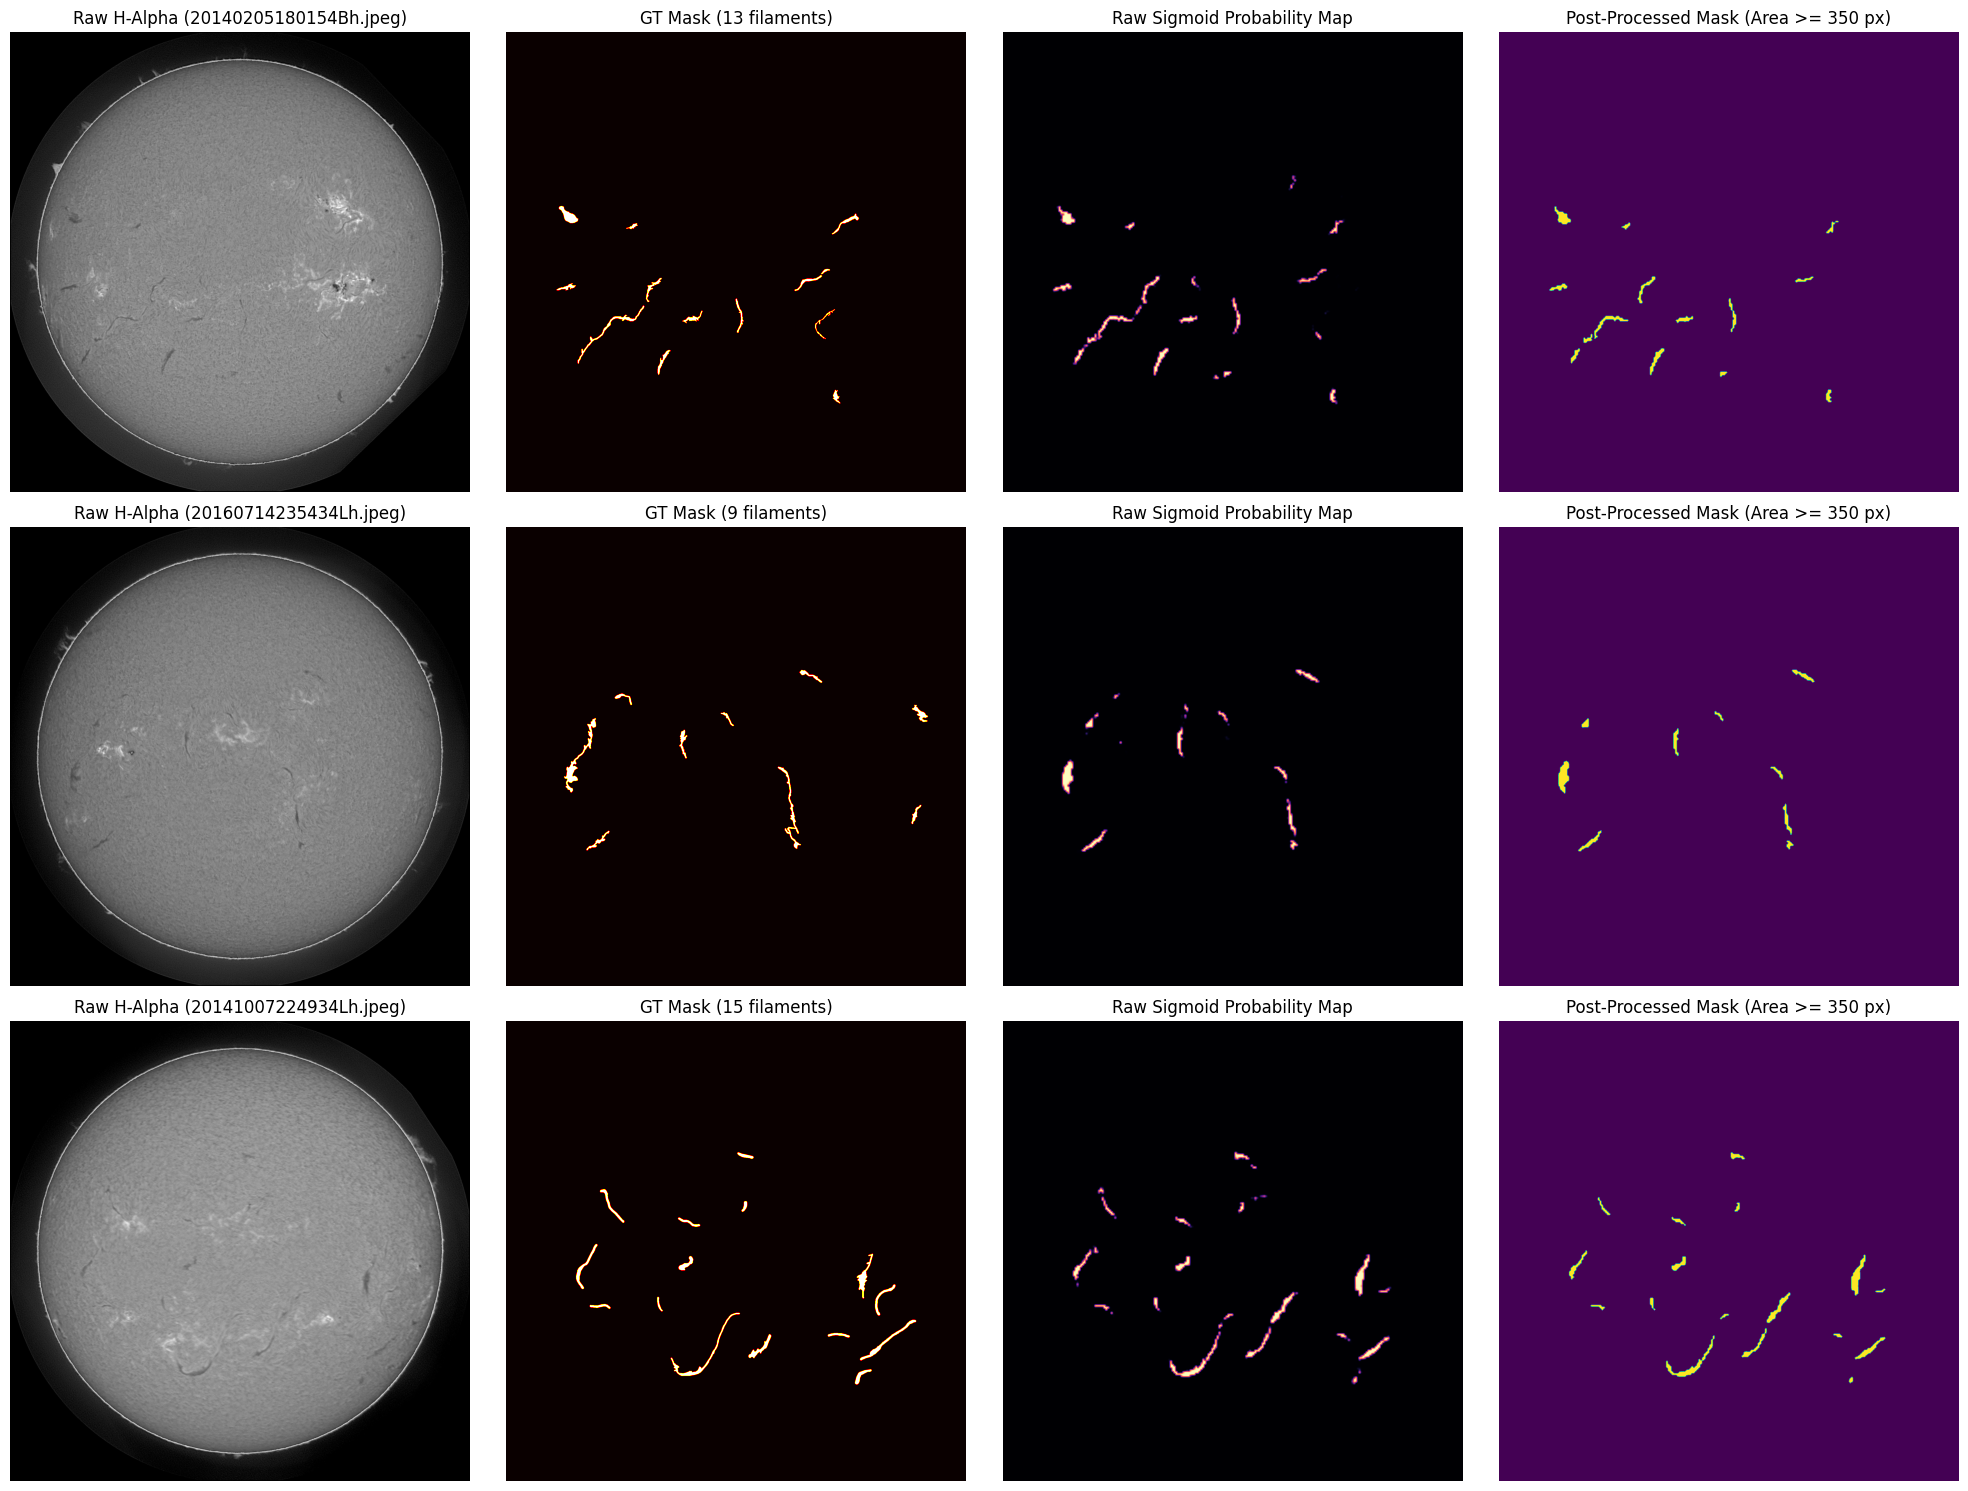

In [12]:
# Qualitative Validation Samples Plot
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
plot_val_samples = val_samples[:3]

for idx, sample in enumerate(plot_val_samples):
    img = Image.open(sample['file_path']).convert("L")
    w, h = sample['width'], sample['height']
    img_np = np.array(img)
    
    # GT Mask
    gt_mask = rasterize_mask(sample['polygons'], w, h)
    
    # Inference
    img_resized = img.resize((config.IMAGE_SIZE, config.IMAGE_SIZE), Image.BILINEAR)
    img_tensor = torch.from_numpy(np.array(img_resized, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)
    
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=(config.DEVICE.type == "cuda")):
            logits = final_model(img_tensor)
            prob_map = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
            
    prob_map_full = cv2.resize(prob_map.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)
    bin_mask = (prob_map_full > config.PRED_THRESHOLD).astype(np.uint8)
    bin_mask_closed = cv2.morphologyEx(bin_mask, cv2.MORPH_CLOSE, morph_kernel)
    
    labeled = label(bin_mask_closed)
    filtered_mask = np.zeros_like(bin_mask_closed)
    for r in regionprops(labeled):
        if r.area >= config.MIN_FILAMENT_AREA:
            filtered_mask[labeled == r.label] = 1
            
    axes[idx, 0].imshow(img_np, cmap="gray")
    axes[idx, 0].set_title(f"Raw H-Alpha ({sample['file_name']})")
    axes[idx, 0].axis("off")
    
    axes[idx, 1].imshow(gt_mask, cmap="hot")
    axes[idx, 1].set_title(f"GT Mask ({sample['filament_count']} filaments)")
    axes[idx, 1].axis("off")
    
    axes[idx, 2].imshow(prob_map_full, cmap="magma")
    axes[idx, 2].set_title("Raw Sigmoid Probability Map")
    axes[idx, 2].axis("off")
    
    axes[idx, 3].imshow(filtered_mask, cmap="viridis")
    axes[idx, 3].set_title("Post-Processed Mask (Area >= 350 px)")
    axes[idx, 3].axis("off")

plt.tight_layout()
plt.show()

## 12. Kaggle Test Set Inference & Formatted Submission Generation

We run inference across all test images and generate `submission_v2.csv` adhering to the competition format:
- `filament_id`: `<image_stem>_<instance_index>` (e.g. `20150125172714Mh_1`)
- `segmentation_rle`: Compressed COCO ASCII RLE string.

In [14]:
def mask_to_coco_rle(binary_mask):
    """
    Encodes a 2D uint8 binary mask into a compressed COCO ASCII RLE string.
    """
    fortran_mask = np.asfortranarray(binary_mask.astype(np.uint8))
    rle = mask_utils.encode(fortran_mask)
    return rle['counts'].decode('utf-8')

# Run Inference on Test Images
test_images = sorted([f for f in os.listdir(config.TEST_IMG_DIR) if f.lower().endswith(('.jpeg', '.jpg', '.png'))])
print(f"Found {len(test_images)} test images in {config.TEST_IMG_DIR}")

submission_rows = []
final_model.eval()

for fname in tqdm(test_images, desc="Test Inference"):
    img_path = config.TEST_IMG_DIR / fname
    img_stem = Path(fname).stem
    
    img = Image.open(img_path).convert("L")
    orig_w, orig_h = img.size
    
    img_resized = img.resize((config.IMAGE_SIZE, config.IMAGE_SIZE), Image.BILINEAR)
    img_tensor = torch.from_numpy(np.array(img_resized, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)
    
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=(config.DEVICE.type == "cuda")):
            logits = final_model(img_tensor)
            prob_map = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
            
    prob_map_full = cv2.resize(prob_map.astype(np.float32), (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
    binary_pred = (prob_map_full > config.PRED_THRESHOLD).astype(np.uint8)
    binary_pred = cv2.morphologyEx(binary_pred, cv2.MORPH_CLOSE, morph_kernel)
    
    labeled_mask = label(binary_pred)
    regions = regionprops(labeled_mask)
    
    # Filter by minimum area
    valid_regions = [r for r in regions if r.area >= config.MIN_FILAMENT_AREA]
    valid_regions = sorted(valid_regions, key=lambda r: r.area, reverse=True)[:config.MAX_FILAMENTS_PER_IMG]
    
    pred_idx = 1
    for region in valid_regions:
        inst_mask = (labeled_mask == region.label).astype(np.uint8)
        rle_str = mask_to_coco_rle(inst_mask)
        submission_rows.append({
            "filament_id": f"{img_stem}_{pred_idx}",
            "segmentation_rle": rle_str
        })
        pred_idx += 1
        
    # Fallback if no filaments exceed threshold
    if pred_idx == 1:
        fallback_mask = (prob_map_full > 0.35).astype(np.uint8)
        labeled_fallback = label(fallback_mask)
        fb_regions = regionprops(labeled_fallback)
        if fb_regions:
            largest_fb = max(fb_regions, key=lambda r: r.area)
            inst_mask = (labeled_fallback == largest_fb.label).astype(np.uint8)
        else:
            inst_mask = np.zeros((orig_h, orig_w), dtype=np.uint8)
            max_y, max_x = np.unravel_index(np.argmax(prob_map_full), prob_map_full.shape)
            inst_mask[max_y, max_x] = 1
            
        submission_rows.append({
            "filament_id": f"{img_stem}_1",
            "segmentation_rle": mask_to_coco_rle(inst_mask)
        })

sub_df = pd.DataFrame(submission_rows, columns=["filament_id", "segmentation_rle"])
sub_df.to_csv(config.SUBMISSION_PATH, index=False)
print(f"\n✅ Saved Submission File to: {config.SUBMISSION_PATH}")
print(f"Total predicted filament instances: {len(sub_df)}")
print(f"Null values in submission: {sub_df.isnull().sum().to_dict()}")
display(sub_df.head(10))

Found 180 test images in MAGFiLO_1.0_Kaggle_2026\test\test_images


Test Inference: 100%|██████████| 180/180 [02:27<00:00,  1.22it/s]


✅ Saved Submission File to: submission_v2.csv
Total predicted filament instances: 1278
Null values in submission: {'filament_id': 0, 'segmentation_rle': 0}


,filament_id,segmentation_rle
0,20110120105534Ch_1,c_`h22mo12N2N2O01O100O4OM2iPNM^n13`QNO_n11aQNO...
1,20110120105534Ch_2,ki`Q22mo12N2N2O00O001OE831O00100O00000_O`01000...
2,20110130110334Ch_1,c_jd23lo12N4M;D2O1O1O010000018G00000O010000018...
3,20110214175414Mh_1,S]`[2:eo12N2N2O0O2N2N2L5M2QOVOeRNl0Ym1VOeRNl0Y...
4,20110214175414Mh_2,c^jd22mo12N101O0O2O0O100O1O1N2O1O1O10000000000...
5,20110214175414Mh_3,cYag2j0Uo12N2N2O0O00000OH9000010O01O1O1N2N2O10...
6,20110214175414Mh_4,[]Ra22mo12N2O1O001O2O1N1O1O10O002N1O001O001O01...
7,20110329082654Uh_1,lWQc29eo13O1N2O010000010cQNDRm1=lRNETm1;jRNGUm...
8,20110329082654Uh_2,cWaU1b0]o12N2N2O1N1O2N3LS1nN2N2N2O0O1O1O1N2N2O...
9,20110329082654Uh_3,Zl`\23jo14L4N2O01000O100O2O0O001O01O0000000000...


# 🏆 Section 13: Official Competition Self-Evaluation & Panoptic Quality (PQ) Metric

This section integrates the exact evaluation harness from the **[Filament Segmentation Challenge 2026](https://www.kaggle.com/competitions/filament-segmentation-2026)**.

It computes:
1. **Panoptic Quality (PQ) Score** on the validation set (IoU > 0.5 threshold matching).
2. **Pairwise IoU Score Distribution** across all matched filament pairs.
3. **Pairwise Dice Score Distribution** across all matched filament pairs.
4. **Many-to-One and One-to-Many Distribution** (analyzing filament fragmentation and merging).

### 13.1 Prepare Validation Ground-Truth (`gt_df`) and Predictions (`pred_df`)

In [15]:
# --- Generate Validation gt_df and pred_df for Self-Evaluation ---
val_gt_rows = []
val_pred_rows = []

final_model.eval()
print("🚀 Generating Validation Ground-Truth & Prediction DataFrames for Self-Evaluation...")

for sample in tqdm(val_samples, desc="Val Self-Evaluation Prep"):
    ann_img_id = sample['image_id']  # e.g., '040301-20140609195854Bh'
    img_stem = Path(sample['file_name']).stem  # e.g., '20140609195854Bh'
    orig_w, orig_h = sample['width'], sample['height']
    
    # 1. Ground Truth individual filament masks
    poly_idx = 1
    for poly in sample['polygons']:
        single_mask = Image.new("L", (orig_w, orig_h), 0)
        draw = ImageDraw.Draw(single_mask)
        draw.polygon(poly, fill=1)
        single_mask_np = np.array(single_mask, dtype=np.uint8)
        if single_mask_np.sum() > 0:
            val_gt_rows.append({
                "filament_id": f"{ann_img_id}_{poly_idx}",
                "segmentation_rle": mask_to_coco_rle(single_mask_np)
            })
            poly_idx += 1
            
    # 2. Model Prediction on this validation image
    img = Image.open(sample['file_path']).convert("L")
    img_resized = img.resize((config.IMAGE_SIZE, config.IMAGE_SIZE), Image.BILINEAR)
    img_tensor = torch.from_numpy(np.array(img_resized, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)
    
    with torch.no_grad():
        with torch.amp.autocast('cuda', enabled=(config.DEVICE.type == "cuda")):
            logits = final_model(img_tensor)
            prob_map = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
            
    prob_map_full = cv2.resize(prob_map.astype(np.float32), (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
    binary_mask = (prob_map_full > config.PRED_THRESHOLD).astype(np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, morph_kernel)
    
    labeled_mask = label(binary_mask)
    regions = regionprops(labeled_mask)
    valid_regions = [r for r in regions if r.area >= config.MIN_FILAMENT_AREA]
    valid_regions = sorted(valid_regions, key=lambda r: r.area, reverse=True)[:config.MAX_FILAMENTS_PER_IMG]
    
    pred_idx = 1
    for region in valid_regions:
        inst_mask = (labeled_mask == region.label).astype(np.uint8)
        val_pred_rows.append({
            "filament_id": f"{img_stem}_{pred_idx}",
            "segmentation_rle": mask_to_coco_rle(inst_mask)
        })
        pred_idx += 1
        
    if pred_idx == 1:
        fallback_mask = (prob_map_full > 0.35).astype(np.uint8)
        labeled_fallback = label(fallback_mask)
        fb_regions = regionprops(labeled_fallback)
        if fb_regions:
            largest_fb = max(fb_regions, key=lambda r: r.area)
            inst_mask = (labeled_fallback == largest_fb.label).astype(np.uint8)
        else:
            inst_mask = np.zeros((orig_h, orig_w), dtype=np.uint8)
            max_y, max_x = np.unravel_index(np.argmax(prob_map_full), prob_map_full.shape)
            inst_mask[max_y, max_x] = 1
        val_pred_rows.append({
            "filament_id": f"{img_stem}_1",
            "segmentation_rle": mask_to_coco_rle(inst_mask)
        })

gt_df = pd.DataFrame(val_gt_rows, columns=["filament_id", "segmentation_rle"])
pred_df = pd.DataFrame(val_pred_rows, columns=["filament_id", "segmentation_rle"])

print(f"✅ Prepared gt_df with {len(gt_df)} GT filaments and pred_df with {len(pred_df)} predicted filaments.")
display(gt_df.head(5))
display(pred_df.head(5))

🚀 Generating Validation Ground-Truth & Prediction DataFrames for Self-Evaluation...


Val Self-Evaluation Prep: 100%|██████████| 173/173 [04:17<00:00,  1.49s/it]

✅ Prepared gt_df with 1324 GT filaments and pred_df with 1322 predicted filaments.


,filament_id,segmentation_rle
0,010401-20140205180154Bh_1,e]oc0>ao11O2N2N0000K3N04N21N1000OO2M3N20WO8ZQN...
1,010401-20140205180154Bh_2,^hf>3jo17K1O2N101O001N101O1O1N3O1N3M2OO01O2N2O...
2,010401-20140205180154Bh_3,Yk^Q11no13N0000O0100000O10O1000000O2ON13K5N000...
3,010401-20140205180154Bh_4,QUoV13bo1N`PN<Yo1:K5J6L5BLeQNZOfm1GcRNP1MWO^m1...
4,010401-20140205180154Bh_5,VXSa11no13N0000000M30001O1O001N2O00L]PNLao15_P...


,filament_id,segmentation_rle
0,20140205180154Bh_1,cYaj0d0;_Obn1e0WQN_Ohn1n0N100O0000O0[OaQNL_n14...
1,20140205180154Bh_2,[h^?7ho1<D2O1N2O01000009HO2N1O1N01OZQN_Onm1a0o...
2,20140205180154Bh_3,c^QZ1R1mn12N2N2O0O00000G18O10010O000000_O0`010...
3,20140205180154Bh_4,SUaV12lo13N2N2N1O2N2I7\Ol0F3M2N101N1O1O1^O]OPS...
4,20140205180154Bh_5,[Umo12jo18Ig0ZO3N2O1O001001O`0I\SN[OZi1e0cVN^O...


### 13.2 Official Evaluation Functions (Pairwise IoU, Dice, FP/FN Matching, & PQ Calculation)

In [16]:
# Helper functions from official Competition Evaluation Notebook
def get_overlap_matrices(gt_layers: torch.Tensor, pred_layers: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """
    Computes pairwise IoU and Dice scores between GT and predicted mask layers.
    """
    n_gt, height, width = gt_layers.shape
    n_pred = pred_layers.shape[0]

    gt_flat = gt_layers.reshape(n_gt, height * width)
    pred_flat = pred_layers.reshape(n_pred, height * width)

    intersection = torch.matmul(gt_flat, pred_flat.t())
    gt_areas = gt_flat.sum(dim=1).view(-1, 1)
    pred_areas = pred_flat.sum(dim=1).view(1, -1)
    union = gt_areas + pred_areas - intersection

    iou_matrix = torch.where(union == 0, torch.tensor(0., device=gt_layers.device), intersection / union)
    dice_matrix = torch.where(union == 0, torch.tensor(0., device=gt_layers.device), 2 * intersection / (gt_areas + pred_areas))
    return iou_matrix, dice_matrix

def fp_count_hit(hit_matrix: torch.Tensor) -> int:
    """Counts false-positive predictions for one image."""
    gt_matches_per_pred = hit_matrix.sum(dim=0)
    return (gt_matches_per_pred == 0).sum().item()
    
def fn_count_hit(hit_matrix: torch.Tensor) -> int:
    """Counts false-negative annotations for one image."""
    pred_matches_per_gt = hit_matrix.sum(dim=1)
    return (pred_matches_per_gt == 0).sum().item()

def rles_to_layers(rles: list[str], height: int = 2048, width: int = 2048) -> np.ndarray:
    """Decode a list of compressed COCO RLE strings into an (n_masks, H, W) binary mask stack."""
    if not rles:
        return np.zeros((0, height, width), dtype=np.uint8)
    layers = []
    for rle_str in rles:
        rle_dict = {'size': [height, width], 'counts': rle_str.encode('utf-8')}
        m = mask_utils.decode(rle_dict)
        layers.append(m)
    return np.stack(layers, axis=0)

def get_pq_score(gt_df: pd.DataFrame, pred_df: pd.DataFrame) -> dict:
    """
    Computes Panoptic Quality (PQ), Segmentation Quality (SQ), and Recognition Quality (RQ).
    """
    gt_df_copy = gt_df.copy()
    pred_df_copy = pred_df.copy()
    
    gt_df_copy['image_id'] = gt_df_copy['filament_id'].apply(lambda x: x.split('_')[0].split('-')[-1])
    pred_df_copy['image_id'] = pred_df_copy['filament_id'].apply(lambda x: x.split('_')[0].split('-')[-1])
    
    unique_images = list(set(gt_df_copy['image_id'].unique()).union(set(pred_df_copy['image_id'].unique())))
    
    total_iou_sum = 0.0
    total_tp = 0
    total_fp = 0
    total_fn = 0
    
    all_matched_ious = []
    all_matched_dices = []
    many_to_one_counts = []
    one_to_many_counts = []
    
    for img_id in tqdm(unique_images, desc="Evaluating Images"):
        gt_rles = gt_df_copy[gt_df_copy['image_id'] == img_id]['segmentation_rle'].tolist()
        pred_rles = pred_df_copy[pred_df_copy['image_id'] == img_id]['segmentation_rle'].tolist()
        
        n_gt = len(gt_rles)
        n_pred = len(pred_rles)
        
        if n_gt == 0 and n_pred == 0:
            continue
        if n_gt == 0 and n_pred > 0:
            total_fp += n_pred
            continue
        if n_gt > 0 and n_pred == 0:
            total_fn += n_gt
            continue
            
        gt_stack = rles_to_layers(gt_rles, 2048, 2048)
        pred_stack = rles_to_layers(pred_rles, 2048, 2048)
        
        gt_t = torch.from_numpy(gt_stack).float()
        pred_t = torch.from_numpy(pred_stack).float()
        
        iou_mat, dice_mat = get_overlap_matrices(gt_t, pred_t)
        
        hit_mat = (iou_mat > 0.5).float()
        
        tp = hit_mat.sum().item()
        fp = fp_count_hit(hit_mat)
        fn = fn_count_hit(hit_mat)
        
        total_tp += int(tp)
        total_fp += int(fp)
        total_fn += int(fn)
        
        matched_indices = torch.nonzero(hit_mat)
        for idx_pair in matched_indices:
            gt_i, pred_j = idx_pair[0].item(), idx_pair[1].item()
            matched_iou = iou_mat[gt_i, pred_j].item()
            matched_dice = dice_mat[gt_i, pred_j].item()
            total_iou_sum += matched_iou
            all_matched_ious.append(matched_iou)
            all_matched_dices.append(matched_dice)
            
        overlap_gt_per_pred = (iou_mat > 0.1).sum(dim=0).cpu().numpy()
        overlap_pred_per_gt = (iou_mat > 0.1).sum(dim=1).cpu().numpy()
        many_to_one_counts.extend(overlap_gt_per_pred.tolist())
        one_to_many_counts.extend(overlap_pred_per_gt.tolist())

    sq = total_iou_sum / total_tp if total_tp > 0 else 0.0
    rq = total_tp / (total_tp + 0.5 * total_fp + 0.5 * total_fn) if (total_tp + 0.5 * total_fp + 0.5 * total_fn) > 0 else 0.0
    pq = sq * rq
    
    return {
        "PQ": pq,
        "SQ": sq,
        "RQ": rq,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "all_matched_ious": all_matched_ious,
        "all_matched_dices": all_matched_dices,
        "many_to_one_counts": many_to_one_counts,
        "one_to_many_counts": one_to_many_counts
    }

print("✅ Official evaluation functions defined.")

✅ Official evaluation functions defined.


### 13.3 Execute Self-Evaluation & Plot Metric Distributions

Evaluating Images: 100%|██████████| 159/159 [02:31<00:00,  1.05it/s]



           🏆 OFFICIAL COMPETITION EVALUATION REPORT   
 Panoptic Quality  (PQ) : 0.3213
 Segmentation Qual (SQ) : 0.6297  (Mean IoU of True Matches)
 Recognition Qual  (RQ) : 0.5102  (F1 Detection Score)
 True Positives    (TP) : 723
 False Positives   (FP) : 680
 False Negatives   (FN) : 708


C:\Users\atiks\AppData\Local\Temp\ipykernel_13228\2437499431.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=eval_results["one_to_many_counts"], ax=axes[1, 0], palette="mako")
C:\Users\atiks\AppData\Local\Temp\ipykernel_13228\2437499431.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=eval_results["many_to_one_counts"], ax=axes[1, 1], palette="flare")


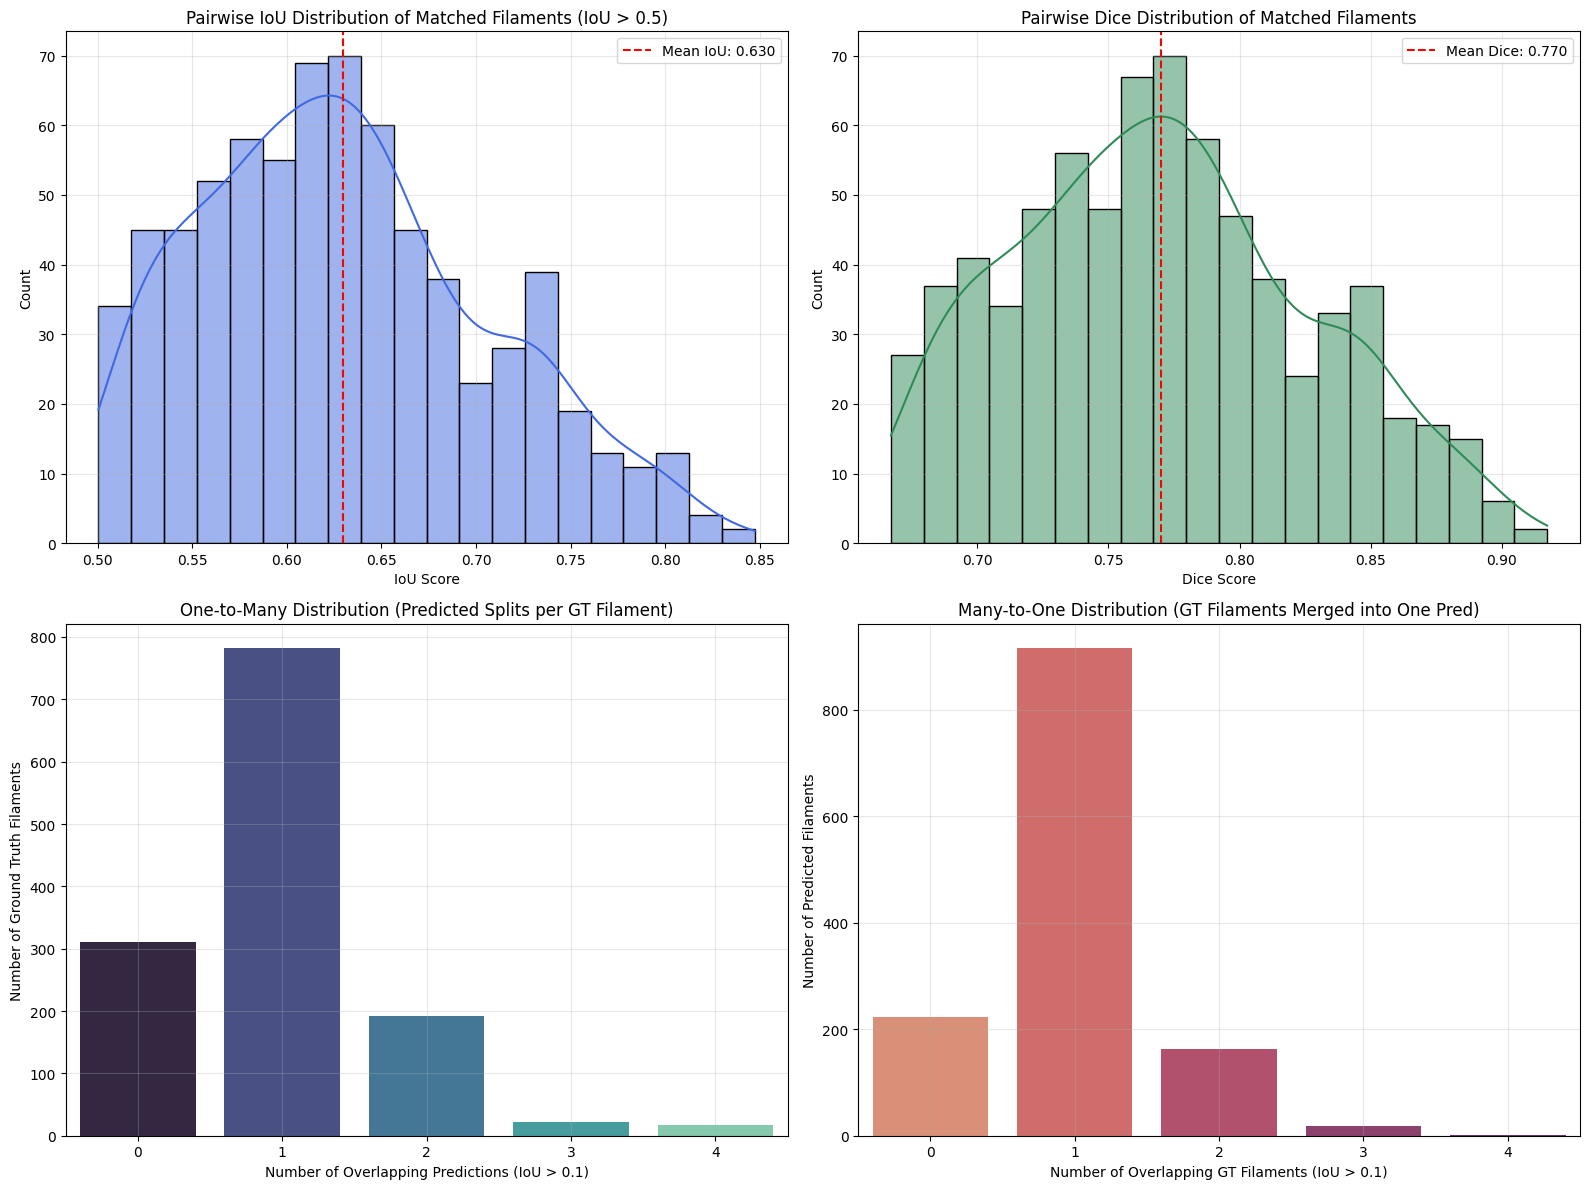

In [17]:
# Compute PQ Score on Validation Set
eval_results = get_pq_score(gt_df, pred_df)

print("\n=======================================================")
print("           🏆 OFFICIAL COMPETITION EVALUATION REPORT   ")
print("=======================================================")
print(f" Panoptic Quality  (PQ) : {eval_results['PQ']:.4f}")
print(f" Segmentation Qual (SQ) : {eval_results['SQ']:.4f}  (Mean IoU of True Matches)")
print(f" Recognition Qual  (RQ) : {eval_results['RQ']:.4f}  (F1 Detection Score)")
print(f" True Positives    (TP) : {eval_results['TP']}")
print(f" False Positives   (FP) : {eval_results['FP']}")
print(f" False Negatives   (FN) : {eval_results['FN']}")
print("=======================================================")

# --- Visual Distribution Graphs ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Pairwise IoU Score Distribution
sns.histplot(eval_results["all_matched_ious"], bins=20, kde=True, ax=axes[0, 0], color="royalblue")
axes[0, 0].axvline(np.mean(eval_results["all_matched_ious"]) if eval_results["all_matched_ious"] else 0, color="red", linestyle="--", label=f"Mean IoU: {np.mean(eval_results['all_matched_ious']):.3f}" if eval_results["all_matched_ious"] else "")
axes[0, 0].set_title("Pairwise IoU Distribution of Matched Filaments (IoU > 0.5)", fontsize=12)
axes[0, 0].set_xlabel("IoU Score")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Pairwise Dice Score Distribution
sns.histplot(eval_results["all_matched_dices"], bins=20, kde=True, ax=axes[0, 1], color="seagreen")
axes[0, 1].axvline(np.mean(eval_results["all_matched_dices"]) if eval_results["all_matched_dices"] else 0, color="red", linestyle="--", label=f"Mean Dice: {np.mean(eval_results['all_matched_dices']):.3f}" if eval_results["all_matched_dices"] else "")
axes[0, 1].set_title("Pairwise Dice Distribution of Matched Filaments", fontsize=12)
axes[0, 1].set_xlabel("Dice Score")
axes[0, 1].set_ylabel("Count")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. One-to-Many Distribution (Filament Splitting)
sns.countplot(x=eval_results["one_to_many_counts"], ax=axes[1, 0], palette="mako")
axes[1, 0].set_title("One-to-Many Distribution (Predicted Splits per GT Filament)", fontsize=12)
axes[1, 0].set_xlabel("Number of Overlapping Predictions (IoU > 0.1)")
axes[1, 0].set_ylabel("Number of Ground Truth Filaments")
axes[1, 0].grid(True, alpha=0.3)

# 4. Many-to-One Distribution (Filament Merging)
sns.countplot(x=eval_results["many_to_one_counts"], ax=axes[1, 1], palette="flare")
axes[1, 1].set_title("Many-to-One Distribution (GT Filaments Merged into One Pred)", fontsize=12)
axes[1, 1].set_xlabel("Number of Overlapping GT Filaments (IoU > 0.1)")
axes[1, 1].set_ylabel("Number of Predicted Filaments")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()